In [2]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# IEX day ahead market, Apr 2024 to Nov 2026
# pulled month by month, exchange caps each export at 31 days

files = sorted(glob.glob("/content/DAM*.xlsx"))
print(len(files), "files")

cols = ["date", "hour", "block", "purchase_bid", "sell_bid",
        "mcv", "scheduled_vol", "mcp"]

all_months = []

for f in files:
    df = pd.read_excel(f, header=None).iloc[5:]
    df.columns = cols
    df = df[df["block"].astype(str).str.contains(":")]   # drops total/max/min/avg rows
    df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")
    df = df.dropna(subset=["date"])
    for c in cols[3:]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    all_months.append(df)

dam = pd.concat(all_months, ignore_index=True)
dam = dam.drop_duplicates(subset=["date", "block"])
dam = dam.sort_values(["date", "block"]).reset_index(drop=True)

dam["blockno"] = dam.groupby("date").cumcount() + 1
dam["month"] = dam["date"].dt.to_period("M")
dam["year"] = dam["date"].dt.year

print(len(dam), "rows")
print(dam["date"].nunique(), "days")
print((dam.groupby("date").size() != 96).sum(), "days not at 96 blocks")
dam.head()

32 files
92736 rows
966 days
0 days not at 96 blocks


,date,hour,block,purchase_bid,sell_bid,mcv,scheduled_vol,mcp,blockno,month,year
0,2024-04-01,1,00:00 - 00:15,11124.9,6318.9,5613.40,5608.40,10000.00,1,2024-04,2024
1,2024-04-01,1,00:15 - 00:30,10976.2,6629.7,5924.19,5919.20,10000.00,2,2024-04,2024
2,2024-04-01,1,00:30 - 00:45,10829.2,7076.6,6227.50,6130.83,9800.25,3,2024-04,2024
3,2024-04-01,1,00:45 - 01:00,10764.4,7371.2,6170.79,6039.84,6254.56,4,2024-04,2024
4,2024-04-01,2,01:00 - 01:15,10714.7,7697.0,6259.50,6128.61,6193.55,5,2024-04,2024


month
2024-04    16.8
2024-05    22.7
2024-06    25.4
2024-07    24.1
2024-08    15.5
2024-09    11.6
2024-10     9.3
2024-11     4.0
2024-12     9.0
2025-01    15.7
2025-02    10.8
2025-03     9.6
2025-04    24.2
2025-05    14.4
2025-06    14.7
2025-07    12.8
2025-08    14.4
2025-09    12.0
2025-10     3.2
2025-11     6.2
2025-12     9.1
2026-01     9.0
2026-02     4.9
2026-03    10.4
2026-04    30.7
2026-05    28.3
2026-06    31.3
2026-07    29.9
2026-08    26.8
2026-09    61.1
2026-10    50.5
2026-11    11.0
Freq: M, Name: at_cap, dtype: float64


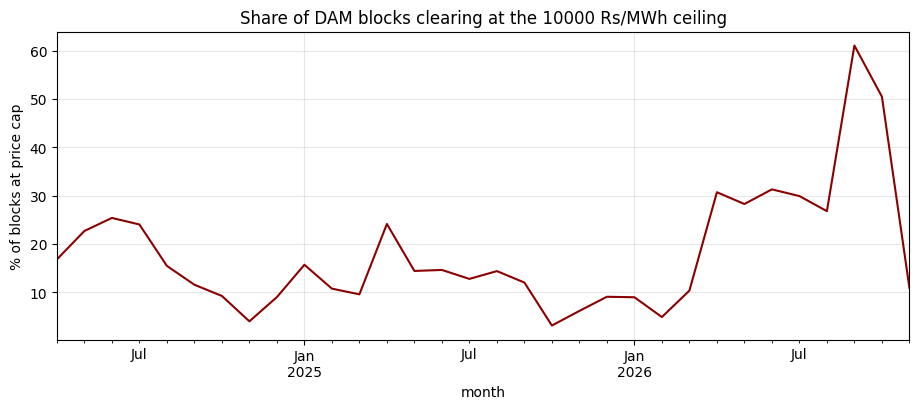

In [3]:
dam["at_cap"] = dam["mcp"] >= 10000

bymonth = dam.groupby("month")["at_cap"].mean() * 100
print(bymonth.round(1))

plt.figure(figsize=(11,4))
bymonth.plot(color="darkred")
plt.ylabel("% of blocks at price cap")
plt.title("Share of DAM blocks clearing at the 10000 Rs/MWh ceiling")
plt.grid(alpha=0.3)
plt.show()

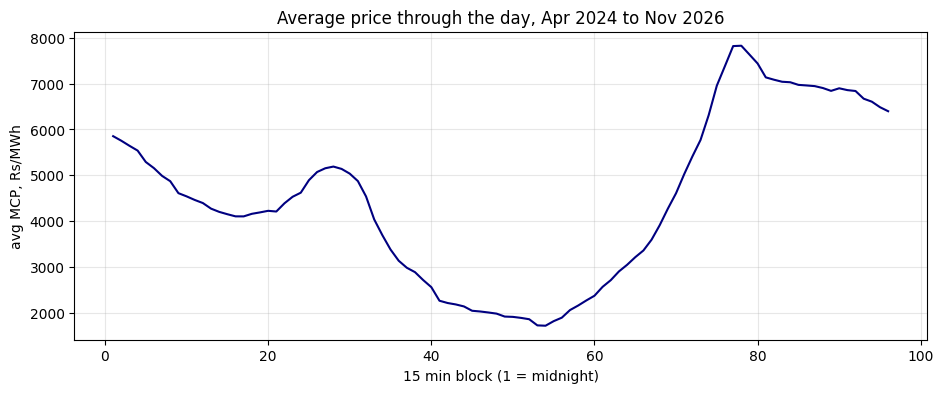

cheapest block: 54 1723
priciest block: 78 7826


In [4]:
shape = dam.groupby("blockno")["mcp"].mean()

plt.figure(figsize=(11,4))
shape.plot(color="navy")
plt.xlabel("15 min block (1 = midnight)")
plt.ylabel("avg MCP, Rs/MWh")
plt.title("Average price through the day, Apr 2024 to Nov 2026")
plt.grid(alpha=0.3)
plt.show()

print("cheapest block:", shape.idxmin(), round(shape.min()))
print("priciest block:", shape.idxmax(), round(shape.max()))

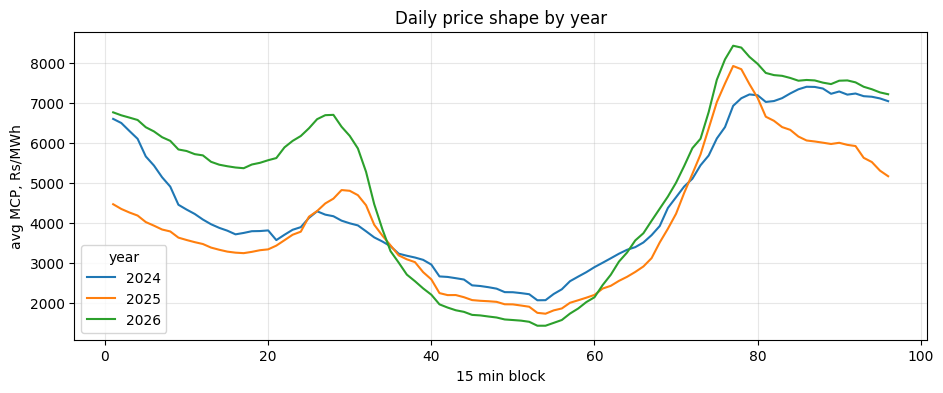

2024 trough 2556 peak 6226 ratio 2.44
2025 trough 2094 peak 6313 ratio 3.02
2026 trough 1894 peak 7080 ratio 3.74


In [5]:
byyear = dam.pivot_table(index="blockno", columns="year", values="mcp", aggfunc="mean")

byyear.plot(figsize=(11,4))
plt.xlabel("15 min block")
plt.ylabel("avg MCP, Rs/MWh")
plt.title("Daily price shape by year")
plt.grid(alpha=0.3)
plt.show()

# solar hours roughly blocks 41 to 64, evening peak 69 to 84
for y in byyear.columns:
    trough = byyear.loc[41:64, y].mean()
    peak = byyear.loc[69:84, y].mean()
    print(y, "trough", round(trough), "peak", round(peak), "ratio", round(peak/trough, 2))

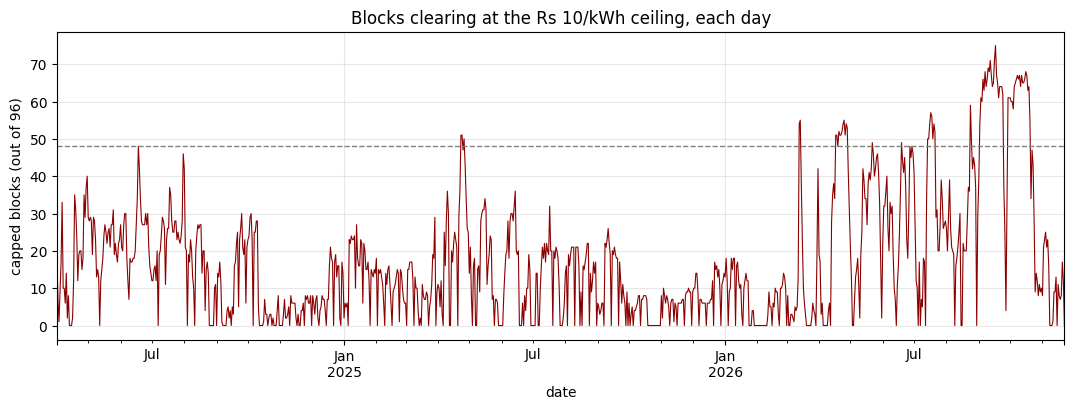

days with no capping: 167
days with 60+ capped blocks: 42
worst day: 2026-09-17 75 blocks

date
2026-09-17    75
2026-09-12    71
2026-09-16    71
2026-09-10    69
2026-10-16    68
2026-09-11    68
2026-09-07    68
2026-09-18    67
2026-09-13    67
2026-10-08    67
Name: at_cap, dtype: int64


In [6]:
dam["at_cap"] = dam["mcp"] >= 10000

daily = dam.groupby("date")["at_cap"].sum()

plt.figure(figsize=(13,4))
daily.plot(color="darkred", lw=0.8)
plt.axhline(48, color="grey", ls="--", lw=1)
plt.ylabel("capped blocks (out of 96)")
plt.title("Blocks clearing at the Rs 10/kWh ceiling, each day")
plt.grid(alpha=0.3)
plt.show()

print("days with no capping:", (daily == 0).sum())
print("days with 60+ capped blocks:", (daily >= 60).sum())
print("worst day:", daily.idxmax().date(), daily.max(), "blocks")
print()
print(daily.sort_values(ascending=False).head(10))

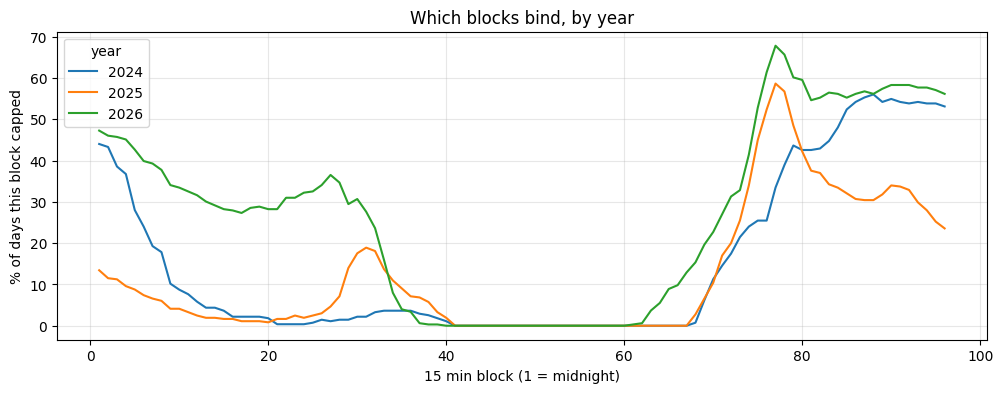

In [7]:
bycap = dam.pivot_table(index="blockno", columns="year", values="at_cap", aggfunc="mean") * 100

bycap.plot(figsize=(12,4))
plt.xlabel("15 min block (1 = midnight)")
plt.ylabel("% of days this block capped")
plt.title("Which blocks bind, by year")
plt.grid(alpha=0.3)
plt.show()

In [8]:
shape = dam.pivot_table(index="blockno", columns="year", values="mcp", aggfunc="mean")

for y in shape.columns:
    charge = shape.loc[41:64, y].mean()
    discharge = shape.loc[69:84, y].mean()
    print(y, "| charge", round(charge), "| discharge", round(discharge),
          "| spread", round(discharge - charge), "| ratio", round(discharge/charge, 2))

2024 | charge 2556 | discharge 6226 | spread 3670 | ratio 2.44
2025 | charge 2094 | discharge 6313 | spread 4219 | ratio 3.02
2026 | charge 1894 | discharge 7080 | spread 5186 | ratio 3.74


        mean  median     max
date                        
2024  3670.0  3830.0  7027.0
2025  4219.0  4495.0  7385.0
2026  5186.0  5424.0  8812.0


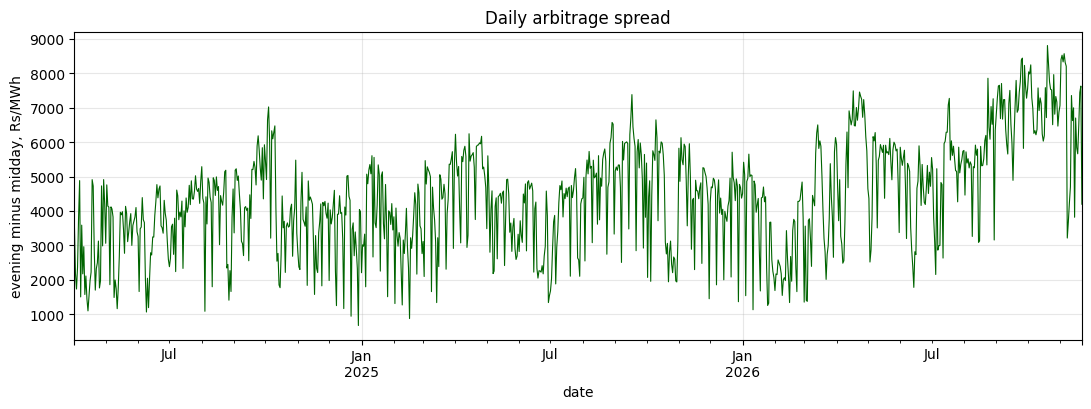

In [9]:
charge = dam[dam["blockno"].between(41,64)].groupby("date")["mcp"].mean()
disch  = dam[dam["blockno"].between(69,84)].groupby("date")["mcp"].mean()
spread = disch - charge

print(spread.groupby(spread.index.year).agg(["mean","median","max"]).round(0))

plt.figure(figsize=(13,4))
spread.plot(color="darkgreen", lw=0.8)
plt.ylabel("evening minus midday, Rs/MWh")
plt.title("Daily arbitrage spread")
plt.grid(alpha=0.3)
plt.show()

In [11]:
dam.to_csv("/content/dam_clean.csv", index=False)
from google.colab import files
files.download("/content/dam_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>